In [ ]:
import os

# Select "cuda" before the first PyRITE import, then restart the kernel.
os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

import pyrite

_ = pyrite.fetch_tables()  # Installed pins are reused without downloading again.

tables_ready = True

# Beams, crystals and target geometry

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/04-beams-crystals-target-geometry.py)

Change one design choice at a time and watch the PXR/CBS source respond:
the **crystal orientation** moves the lines, while **target thickness**
and the **beam spot** relative to the target footprint change how much
radiation each incident electron produces.

`TransverseSpot` sets a round Gaussian entrance spot by its **FWHM** in mm;
`Slab` uses explicit Pint lengths and angles at the public boundary.
`CrystalCut` fixes which lattice axis is normal to the surface.

In [ ]:
assert tables_ready  # Wait for reference-table installation before transport.
from pyrite import simulate
from pyrite.beams import Beam, PointBunch, TransverseSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics, Physics
from pyrite.detectors import Detector
from pyrite.geometry import CrystalCut, Footprint, Slab
from pyrite.units import ureg

detector = Detector(observation_angle=135 * ureg.degree)
band_eV = (600.0, 2_000.0)


def source(*, tilt_deg=30.0, thickness_nm=100.0, spot_fwhm_mm=0.45, histories=2_048):
    """PXR/CBS source for a 30 keV beam on a 2 mm × 2 mm HOPG (002) slab."""
    beam = Beam(
        kinetic_energy=30 * ureg.keV,
        transverse=TransverseSpot(fwhm_x=spot_fwhm_mm * ureg.mm),
        longitudinal=PointBunch(),
    )
    target = Slab(
        "hopg",
        thickness=thickness_nm * ureg.nm,
        tilt=tilt_deg * ureg.degree,
        footprint=Footprint(width=2 * ureg.mm, height=2 * ureg.mm),
        cut=CrystalCut(beam_uvw=(0, 0, 2)),
    )
    result = simulate(
        beam,
        target,
        detector,
        physics=Physics(brem_source="none"),  # isolate PXR/CBS
        numerics=Numerics(
            sampling=FixedSampling(cxr_electrons=histories, brem_electrons=histories),
            cxr_reflections=CxrReflections(n_families=2),
        ),
    )
    return result.cxr.incoherent


def band_yield(spectrum):
    """Photons / (incident electron · sr) in the band, with interpolated edges."""
    grid, lo, hi = spectrum.photon_energy_eV, *band_eV
    nodes = np.r_[lo, grid[(grid > lo) & (grid < hi)], hi]
    return float(np.trapezoid(np.interp(nodes, grid, spectrum.density), nodes))

## Crystal orientation moves the lines

Simulate three tilts and mark the ideal (002) and (004) line centers from
`photon_energies()` (notebook 03) on each spectrum.

In [ ]:
assert tables_ready  # Wait for reference-table installation before transport.
from pyrite.radiation import photon_energies

tilts_deg = (20.0, 30.0, 40.0)
tilt_spectra = [source(tilt_deg=_tilt) for _tilt in tilts_deg]
predicted_eV = np.array(
    [
        photon_energies("hopg", 30_000.0, tilt_deg=list(tilts_deg), theta_obs_deg=135.0, hkl=_hkl)[
            0
        ]
        for _hkl in ((0, 0, 2), (0, 0, 4))
    ]
)  # shape: (reflection, tilt)

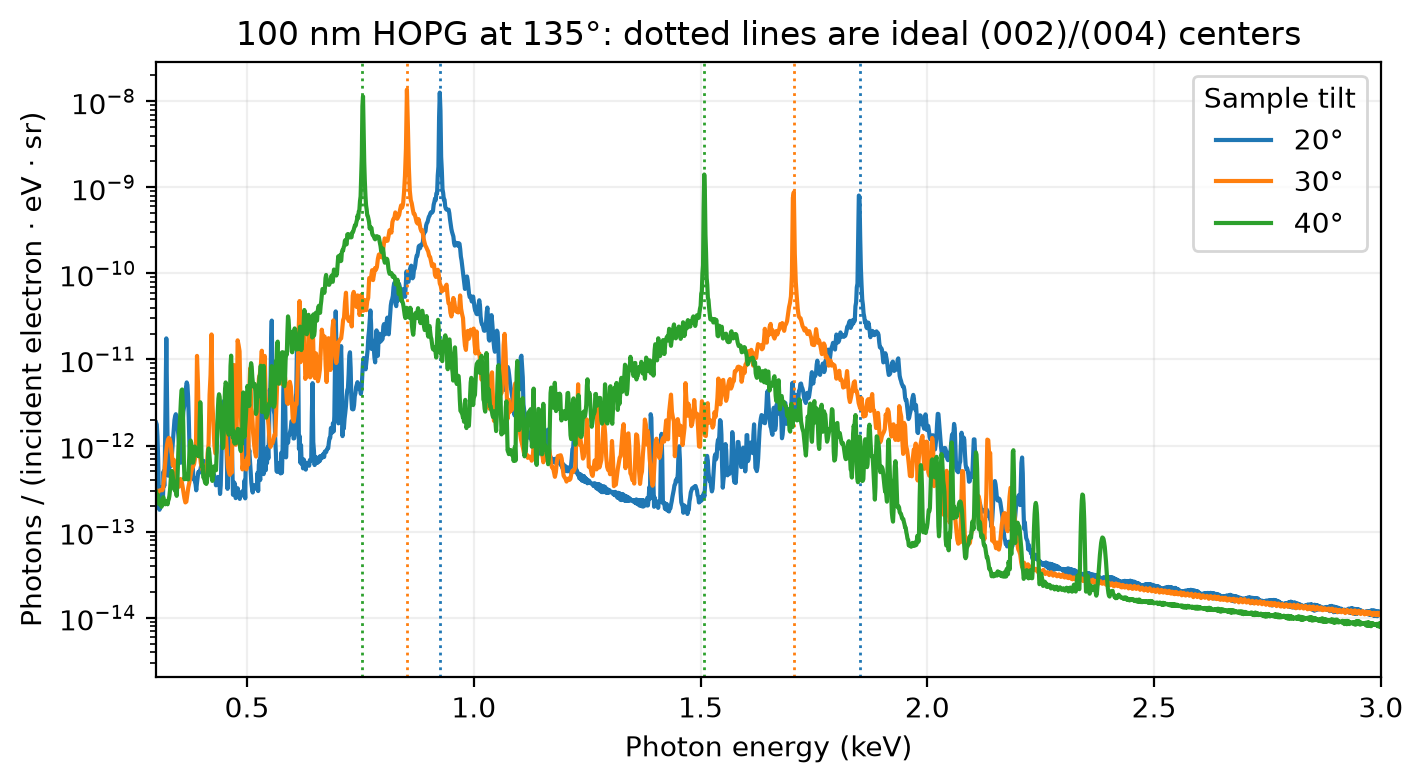

In [ ]:
fig_tilt, _ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
for _i, (_tilt, _spectrum) in enumerate(zip(tilts_deg, tilt_spectra, strict=True)):
    _ax.plot(
        _spectrum.photon_energy_eV / 1_000,
        _spectrum.density,
        color=f"C{_i}",
        label=f"{_tilt:g}°",
    )
    for _line_eV in predicted_eV[:, _i]:
        _ax.axvline(_line_eV / 1_000, color=f"C{_i}", ls=":", lw=1)
_ax.set(
    xlabel="Photon energy (keV)",
    ylabel="Photons / (incident electron · eV · sr)",
    title="100 nm HOPG at 135°: dotted lines are ideal (002)/(004) centers",
    xlim=(0.3, 3.0),
    yscale="log",
)
_ax.legend(title="Sample tilt")
_ax.grid(alpha=0.2)
fig_tilt  # noqa: B018 - marimo renders the final expression

## Thickness and spot size set the yield

Integrate the band yield for five thicknesses and two spots on the same
2 mm footprint: a 0.45 mm spot that lands entirely on the crystal and a
4 mm spot that overfills it.

In [ ]:
assert tables_ready
thicknesses_nm = np.array([25.0, 50.0, 100.0, 200.0, 400.0])
spots_mm = (0.45, 4.0)
thickness_yield = np.array(
    [
        [
            band_yield(source(thickness_nm=_t, spot_fwhm_mm=_spot, histories=1_024))
            for _t in thicknesses_nm
        ]
        for _spot in spots_mm
    ]
)

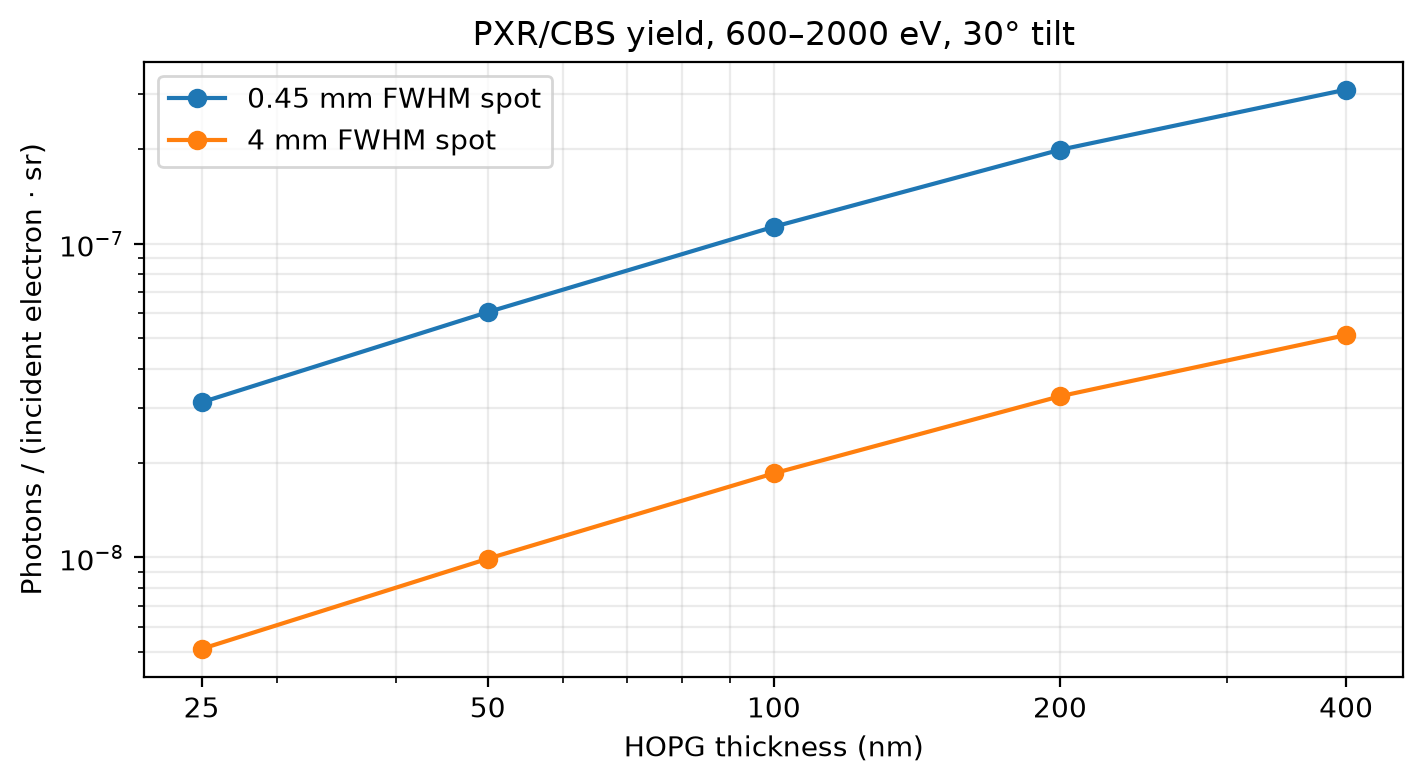

In [ ]:
from matplotlib.ticker import NullFormatter

fig_thickness, _ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
for _spot, _yields in zip(spots_mm, thickness_yield, strict=True):
    _ax.plot(thicknesses_nm, _yields, "o-", label=f"{_spot:g} mm FWHM spot")
_ax.set(
    xscale="log",
    yscale="log",
    xlabel="HOPG thickness (nm)",
    ylabel="Photons / (incident electron · sr)",
    title=f"PXR/CBS yield, {band_eV[0]:g}–{band_eV[1]:g} eV, 30° tilt",
    xticks=thicknesses_nm,
    xticklabels=[f"{_t:g}" for _t in thicknesses_nm],
)
_ax.xaxis.set_minor_formatter(NullFormatter())
_ax.legend()
_ax.grid(alpha=0.25, which="both")
fig_thickness  # noqa: B018 - marimo renders the final expression

In [ ]:
_ratio = thickness_yield[1] / thickness_yield[0]
mo.md(
    f"The {spots_mm[1]:g} mm spot yields **{_ratio.min():.3f}× to {_ratio.max():.3f}×** "
    f"the {spots_mm[0]:g} mm yield per incident electron across these thicknesses."
)

The 4 mm spot yields **0.164× to 0.165×** the 0.45 mm yield per incident electron across these thicknesses.

## Interpretation

Tilting the crystal rotates the reciprocal vector, so each line moves with
tilt exactly as the analytic centers predict; transport and absorption shape
the peaks but not their positions. Yield grows with thickness because each
electron crosses more radiating lattice, but more slowly than linearly once
multiple scattering, energy loss and photon self-absorption matter.

Yields are normalized **per incident electron**, including electrons that
miss the crystal. Only about one electron in six from the 4 mm spot lands
on the tilted 2 mm footprint, so its yield falls by that same factor at
every thickness: a geometric loss, not a change in emission physics. All runs use the default seed 1 and
1,024–2,048 histories, so differences of a few percent are within sampling
noise (notebook 07). Results are response-free source quantities, not counts.

Try a different `material` (other crystals may need another `CrystalCut` and
energy window) or rerun the tilt series at 60 keV.

## Continue learning

Next: [Angular radiation distributions](05-angular-radiation-distributions.ipynb).
Use the [beam API](../../reference/python-api/beams.md) and
[geometry API](../../reference/python-api/geometry.md) to configure inputs.
[Beam phase space](../../physics/beam-transport/beam-phase-space.md) and
[transport geometry](../../physics/geometry/transport-geometry.md) explain the
coordinates; [beam-injection evidence](../../validation/beam-transport/beam-phase-space-injection.md)
records the sampling checks.

{download}`Download canonical Marimo notebook <../04-beams-crystals-target-geometry.py>`